# EDA of the Abalone dataset

Goal: understand the data before predicting the age of an abalone.
The target is `Rings`: age in years ≈ `Rings` + 1.5.

## Imports

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 500)

## Data

In [2]:
df = pd.read_csv("../data/abalone.csv")
df.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   str    
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), str(1)
memory usage: 297.9 KB


In [4]:
print("Missing values:", df.isna().sum().sum())
print("Duplicated rows:", df.duplicated().sum())
df.describe().T

Missing values: 0
Duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
Length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
Diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
Height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
Whole weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
Shucked weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
Viscera weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
Shell weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
Rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


## Target: number of rings

Most abalones have between 8 and 11 rings, with a long tail of old individuals (up to 29).

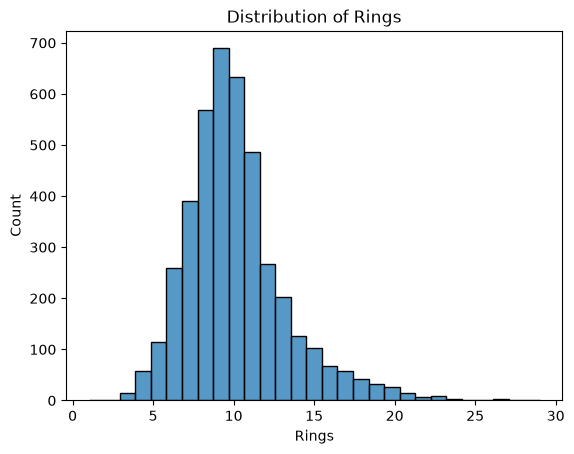

In [5]:
sns.histplot(df["Rings"], bins=29)
plt.title("Distribution of Rings")
plt.show()

## Sex (M = male, F = female, I = infant)

The three categories are balanced. Infants have clearly fewer rings, so `Sex` is useful for the model.

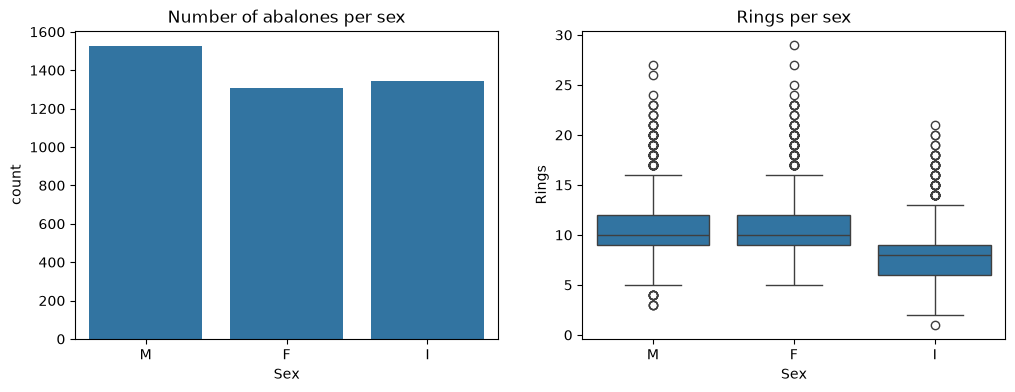

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Sex", ax=axes[0])
sns.boxplot(data=df, x="Sex", y="Rings", ax=axes[1])
axes[0].set_title("Number of abalones per sex")
axes[1].set_title("Rings per sex")
plt.show()

## Relationship between the measurements and the target

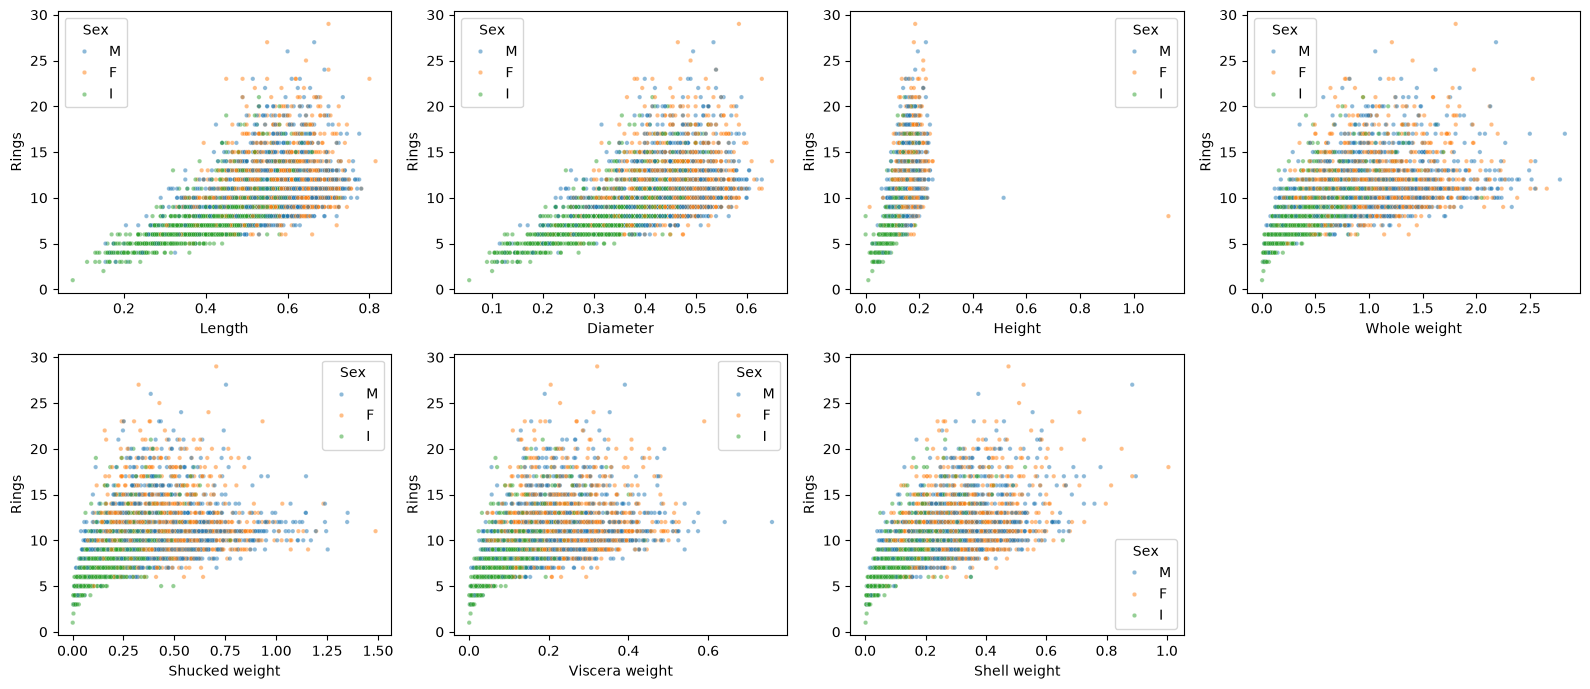

In [7]:
numeric_features = df.columns.drop(["Sex", "Rings"])

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for feature, ax in zip(numeric_features, axes.flat):
    sns.scatterplot(data=df, x=feature, y="Rings", hue="Sex", s=10, alpha=0.5, ax=ax)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

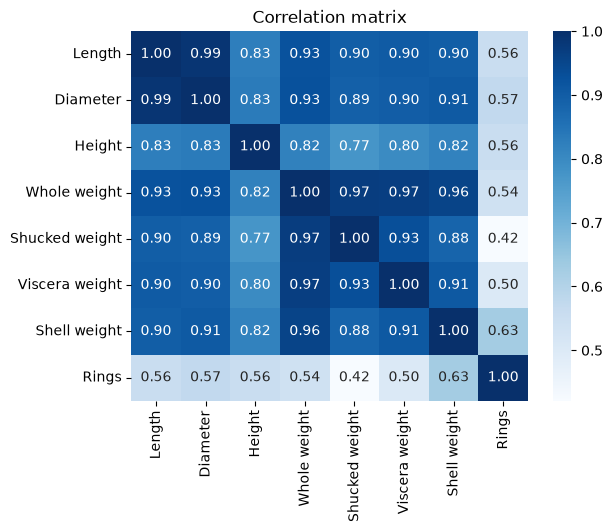

In [8]:
sns.heatmap(df.drop(columns="Sex").corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Correlation matrix")
plt.show()

## Outliers in `Height`

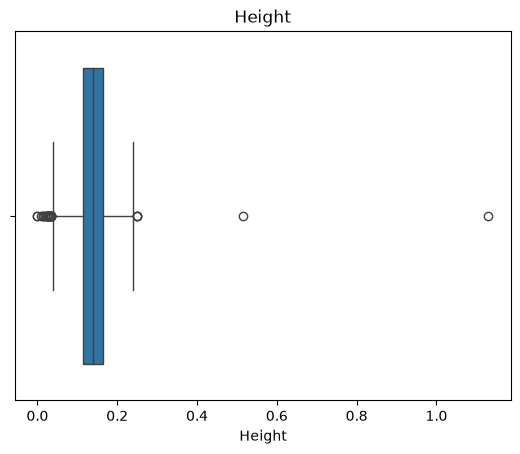

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.340,0.000,0.428,0.2065,0.0860,0.1150,8
1417,M,0.705,0.565,0.515,2.210,1.1075,0.4865,0.5120,10
2051,F,0.455,0.355,1.130,0.594,0.3320,0.1160,0.1335,8
3996,I,0.315,0.230,0.000,0.134,0.0575,0.0285,0.3505,6


In [9]:
sns.boxplot(x=df["Height"])
plt.title("Height")
plt.show()

df[(df["Height"] == 0) | (df["Height"] > 0.4)]

## Conclusions

- The dataset is clean: 4,177 rows, no missing values and no duplicates.
- The target `Rings` ranges from 1 to 29, mostly between 8 and 11, with a right tail of old abalones.
- All measurements are positively correlated with `Rings`; `Shell weight` is the best predictor (0.63).
  The relationship is not perfectly linear: rings spread out a lot for large abalones.
- The measurements are very strongly correlated with each other (> 0.8), since they all describe the size of the abalone.
- `Sex` matters: infants (`I`) have fewer rings than adults. It is categorical, so it must be one-hot encoded.
- `Height` has 2 rows equal to 0 (impossible) and 2 extreme values (> 0.4): we remove the zero heights before modelling.